In [31]:
try:
    from google.colab import output
    print('Running on CoLab')
    #%pip install roboticstoolbox-python>=1.0.2
    %pip install git+https://github.com/petercorke/robotics-toolbox-python@future
    %pip install spatialmath-python>=1.1.5
    %pip install --no-deps rvc3python
    %pip install bdsim
    COLAB = True
except ModuleNotFoundError:
    COLAB = False

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "last_expr_or_assign"

%matplotlib widget

In [32]:
from IPython.display import HTML

import matplotlib.pyplot as plt

# add RTB examples folder to the path
import sys, os.path
import RVC3 as rvc
models_dir = os.path.join(rvc.__path__[0], 'models')
sys.path.append(models_dir)

# ------ standard imports ------ #
import numpy as np
import math
from math import pi
np.set_printoptions(
    linewidth=120, formatter={
        'float': lambda x: f"{0:8.4g}" if abs(x) < 1e-10 else f"{x:8.4g}"})
np.random.seed(0)
from spatialmath import *
from spatialmath.base import *
from roboticstoolbox import *

### Car-Like Vehicle

┌────────────┬────┬────┬───────────┬────────┬──────────┬─────────────────────┐
│   block    │ nc │ nd │   type    │ inport │  source  │     source type     │
├────────────┼────┼────┼───────────┼────────┼──────────┼─────────────────────┤
│ scopexy1.0 │ 0  │ 0  │ scopexy1  │ 0      │ vehicle  │ ndarray(3,).float64 │
├────────────┼────┼────┼───────────┼────────┼──────────┼─────────────────────┤
│ speed      │ 0  │ 0  │ constant  │        │          │                     │
├────────────┼────┼────┼───────────┼────────┼──────────┼─────────────────────┤
│ steering@  │ 0  │ 0  │ piecewise │        │          │                     │
├────────────┼────┼────┼───────────┼────────┼──────────┼─────────────────────┤
│ vehicle    │ 3  │ 0  │ bicycle   │ 0      │ speed    │ int                 │
│            │    │    │           │ 1      │ steering │ int                 │
└────────────┴────┴────┴───────────┴────────┴──────────┴─────────────────────┘

Note: @ = event source


>>> Start simulation: T = 

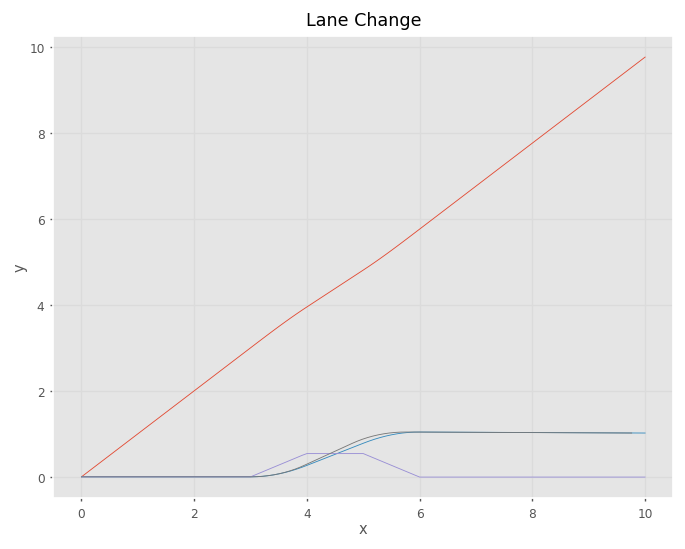

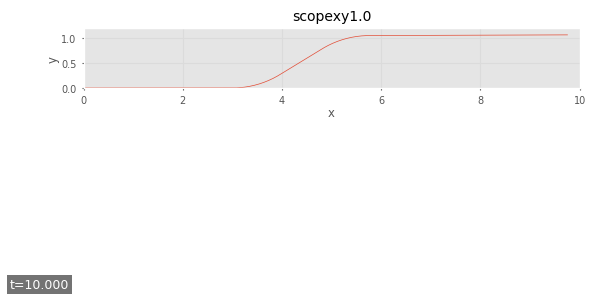


<<< Simulation complete
  block diagram evaluations: 1877
    of which ydot calls:     1666  (remaining are post-integration replay + sink passes)
  bd.evaluate() mean time:   188.8 us/call  (total 354.4 ms)
  clocktime speedup:         0.44x  (simulated 10s in 22756.2 ms)
  integration time points:   211
  scheduled event intervals: 200  (each bounded by a clock tick, scheduled event, or terminal marker)
  integrator wall time:       0.466 s  (solve_ivp only; excludes post-integration replay)
  zero-crossing events:      0



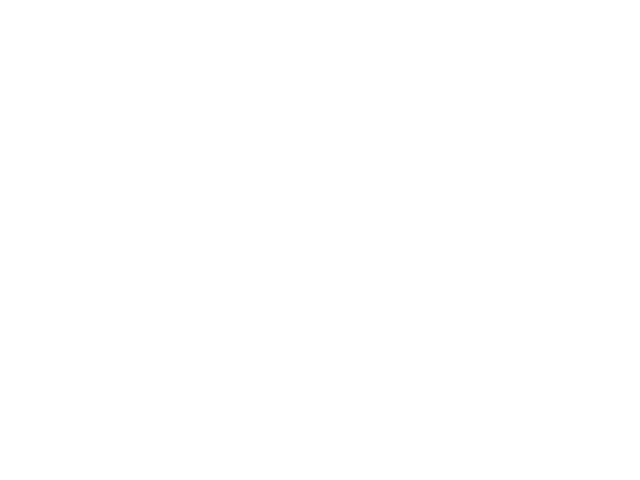

In [34]:
%run -i "models_dir\lanechange.py"

In [25]:
out

t      = ndarray:float64 (115,)
x      = ndarray:float64 (115, 3)
xnames = ['x', 'y', '$\\theta$'] (list)

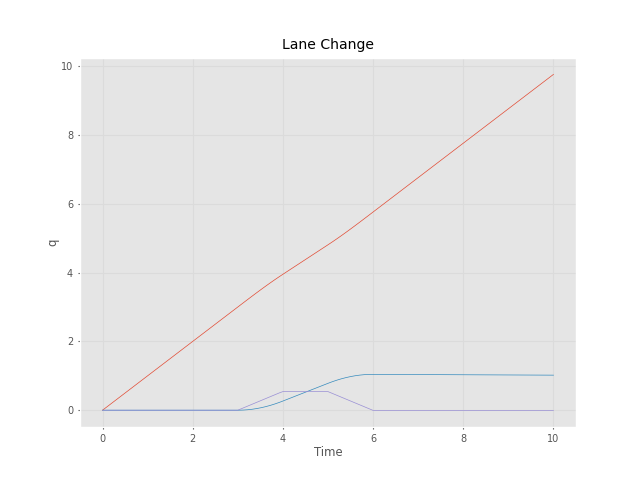

In [26]:
plt.plot(out.t, out.x)  # q vs time
plt.xlabel('Time')
plt.ylabel('q')
plt.title('Lane Change')
plt.show()

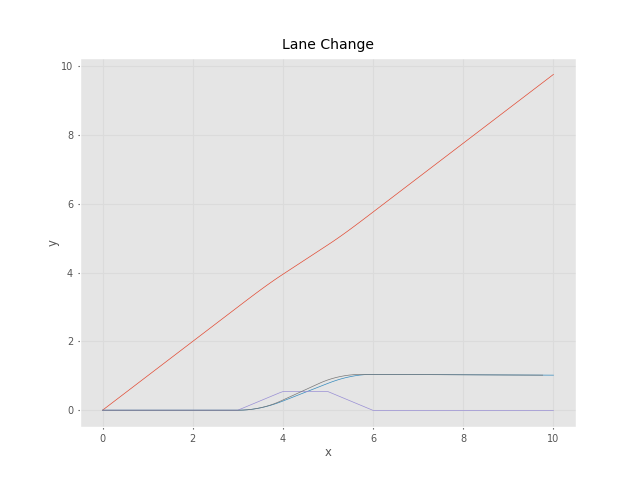

In [27]:
plt.plot(out.x[:,0], out.x[:,1])# x vs y
plt.xlabel('x')
plt.ylabel('y')
plt.title('Lane Change')
plt.show()

#### Driving to a Point

In [28]:
pgoal = (5, 5)

(5, 5)

In [29]:
qs = (8, 5, pi/2)

(8, 5, 1.5707963267948966)

┌───────────────┬────┬────┬─────────────┬────────┬────────────┬─────────────────────┐
│     block     │ nc │ nd │    type     │ inport │   source   │     source type     │
├───────────────┼────┼────┼─────────────┼────────┼────────────┼─────────────────────┤
│ function.0    │ 0  │ 0  │ function    │ 0      │ sum.0      │ ndarray(2,).float64 │
├───────────────┼────┼────┼─────────────┼────────┼────────────┼─────────────────────┤
│ function.1    │ 0  │ 0  │ function    │ 0      │ sum.0      │ ndarray(2,).float64 │
├───────────────┼────┼────┼─────────────┼────────┼────────────┼─────────────────────┤
│ gain.0        │ 0  │ 0  │ gain        │ 0      │ function.0 │ float               │
├───────────────┼────┼────┼─────────────┼────────┼────────────┼─────────────────────┤
│ gain.1        │ 0  │ 0  │ gain        │ 0      │ sum.1      │ float               │
├───────────────┼────┼────┼─────────────┼────────┼────────────┼─────────────────────┤
│ goal          │ 0  │ 0  │ constant    │        │    

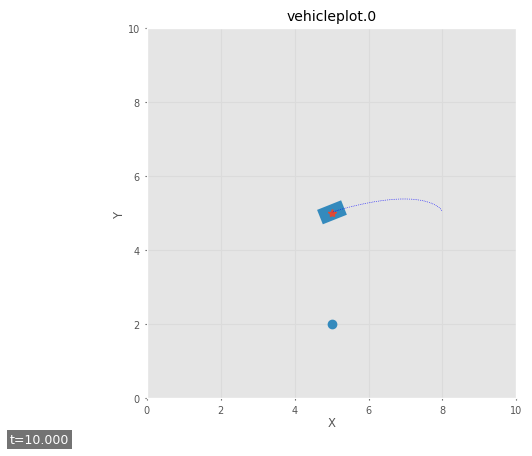

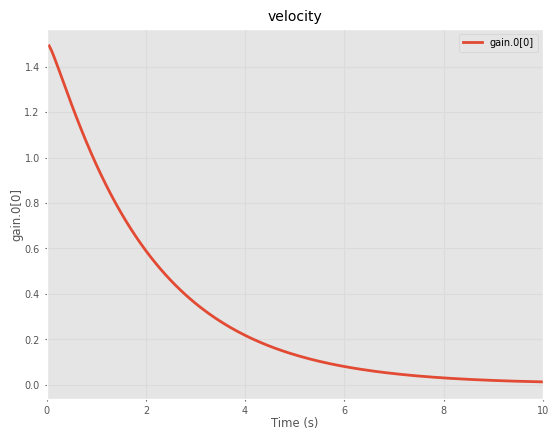

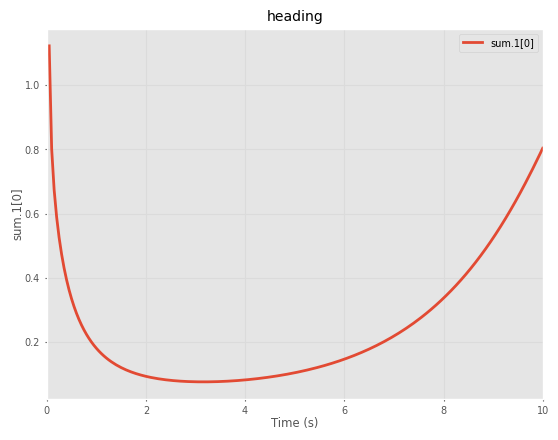


<<< Simulation complete
  block diagram evaluations: 1800
    of which ydot calls:     1600  (remaining are post-integration replay + sink passes)
  bd.evaluate() mean time:   366.4 us/call  (total 659.5 ms)
  clocktime speedup:         0.25x  (simulated 10s in 40217.7 ms)
  integration time points:   200
  scheduled event intervals: 200  (each bounded by a clock tick, scheduled event, or terminal marker)
  integrator wall time:       0.742 s  (solve_ivp only; excludes post-integration replay)
  zero-crossing events:      0



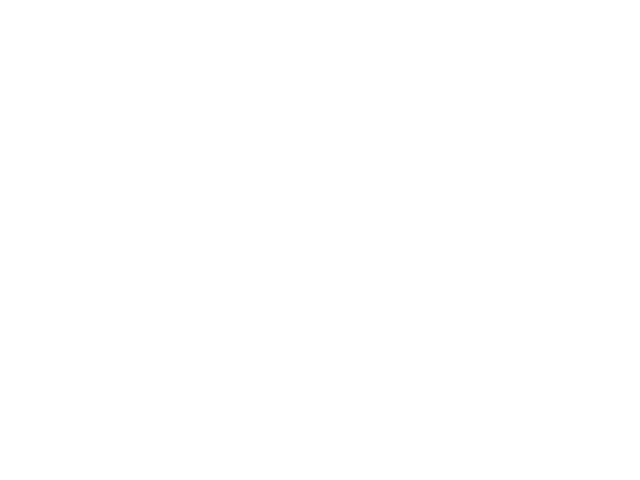

In [35]:
%run -i "models_dir/drivepoint.py"

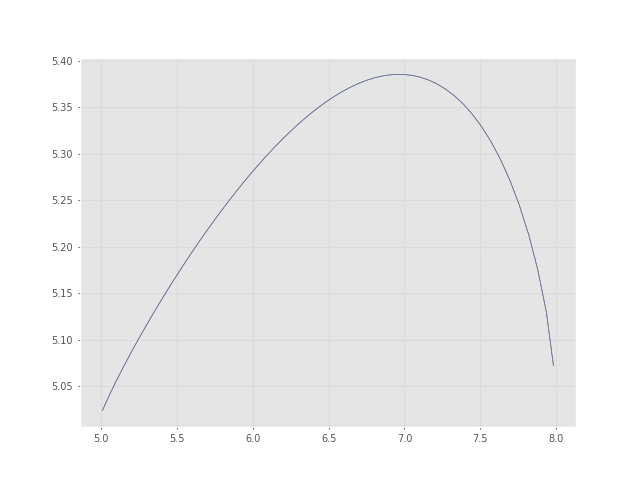

In [ ]:
q = out.x
plt.plot(q[:,0], q[:, 1])
plt.show()